# XgBoost Model


### Importing libraries and clean dataset

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, r2_score

### Encoding and splitting the dataset

In [13]:
df = pd.read_csv("/content/Life Expectancy Data.csv")
df.columns = df.columns.str.strip()

df = df.dropna(subset=['Life expectancy'])   # ← ADD THIS LINE

df_encoded = pd.get_dummies(df, drop_first=True)
df_encoded = df_encoded.astype(float)

X = df_encoded.drop(columns=['Life expectancy'])
y = df_encoded['Life expectancy']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Setting up the model

In [14]:
# Define the base XGBoost model
xgb_base = XGBRegressor(random_state=42)

# Tuning
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'n_estimators': [100, 200, 300]
}

# Setup 5-Fold Cross-Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Instantiate GridSearchCV
# n_jobs=-1 uses all available CPU cores to speed up training
grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    cv=kf,
    scoring='neg_root_mean_squared_error', # We optimize for the lowest RMSE
    n_jobs=-1,
    verbose=1
)

print("\nStarting Hyperparameter Tuning and 5-Fold Cross-Validation...")
grid_search.fit(X_train, y_train)


# The best model found by GridSearchCV
best_model = grid_search.best_estimator_


print(f"Best Hyperparameters Found: {grid_search.best_params_}")

# Making predictions
y_pred = best_model.predict(X_test)

# Calculating metrics
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
final_r2 = r2_score(y_test, y_pred)

print(f"Final Model RMSE on Test Set: {final_rmse:.2f} years")
print(f"Final Model R-Squared (R²): {final_r2:.4f}")
print("==========================================")


Starting Hyperparameter Tuning and 5-Fold Cross-Validation...
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best Hyperparameters Found: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 300}
Final Model RMSE on Test Set: 1.56 years
Final Model R-Squared (R²): 0.9718


### Model Evaluation & Visualizations

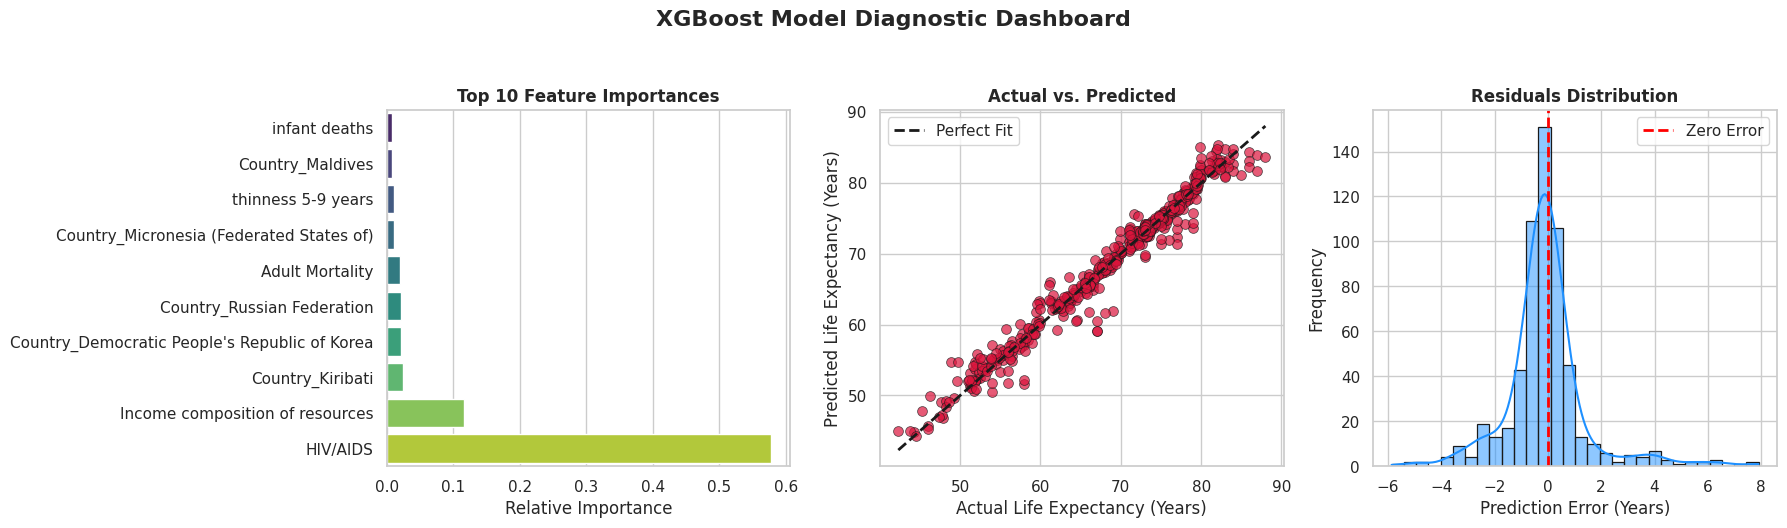

In [15]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11})


fig, axes = plt.subplots(1, 3, figsize=(18, 5))


importances = best_model.feature_importances_
features = X.columns

indices = np.argsort(importances)[-10:]

sns.barplot(x=importances[indices], y=features[indices], hue=features[indices], palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Top 10 Feature Importances", fontweight='bold')
axes[0].set_xlabel("Relative Importance")
axes[0].set_ylabel("")

sns.scatterplot(x=y_test, y=y_pred, alpha=0.7, color="crimson", edgecolor="k", s=50, ax=axes[1])

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
axes[1].plot([min_val, max_val], [min_val, max_val], 'k--', lw=2, label="Perfect Fit")

axes[1].set_title("Actual vs. Predicted", fontweight='bold')
axes[1].set_xlabel("Actual Life Expectancy (Years)")
axes[1].set_ylabel("Predicted Life Expectancy (Years)")
axes[1].legend()

residuals = y_test - y_pred
sns.histplot(residuals, bins=30, kde=True, color="dodgerblue", edgecolor="k", ax=axes[2])
axes[2].axvline(x=0, color='red', linestyle='--', lw=2, label="Zero Error")

axes[2].set_title("Residuals Distribution", fontweight='bold')
axes[2].set_xlabel("Prediction Error (Years)")
axes[2].set_ylabel("Frequency")
axes[2].legend()



fig.suptitle("XGBoost Model Diagnostic Dashboard", fontsize=16, fontweight='bold', y=1.05)


plt.tight_layout()


plt.savefig("Combined_Model_Diagnostics.png", dpi=300, bbox_inches='tight')
plt.show()

### Making Our Own Prediction What-If

In [16]:

print(" Our Scenario ")

utopia = X.mean().to_frame().T

# 18 years of schooling
utopia['Schooling'] = 18.0

# Minimizing HIV/AIDS rates
if 'HIV/AIDS' in utopia.columns:
    utopia['HIV/AIDS'] = 0.1

# Reseting infant deaths to 0
if 'infant deaths' in utopia.columns:
    utopia['infant deaths'] = 0

# Gelir endeksini (Income composition of resources) en üst düzeye (0.95) çıkaralım
if 'Income composition of resources' in utopia.columns:
    utopia['Income composition of resources'] = 0.95

# Modelden tahmini alalım
utopia_predict = best_model.predict(utopia)[0]

print(f"\nScenario: No infants are dying, everyone has education and income is high")
print(f"XGBoost prediction for this utopia: {utopia_predict:.1f} years.")

 Our Scenario 

Scenario: No infants are dying, everyone has education and income is high
XGBoost prediction for this utopia: 71.7 years.


In [17]:
!pip install wandb -q
import wandb
from sklearn.metrics import mean_absolute_error
wandb.login()

run = wandb.init(entity="ml-group-j",
                 project="life-expectancy-ml",
                 name="xgboost",
                 config=grid_search.best_params_)

# Retrain the best model with eval tracking to get per-round training curves
best = XGBRegressor(random_state=42, **grid_search.best_params_)
best.fit(X_train, y_train,
         eval_set=[(X_train, y_train), (X_test, y_test)],
         verbose=False)

hist = best.evals_result()
for i in range(len(hist["validation_0"]["rmse"])):
    wandb.log({"boosting_round": i,
               "train_RMSE_curve": hist["validation_0"]["rmse"][i],
               "test_RMSE_curve": hist["validation_1"]["rmse"][i]})

wandb.log({"test_R2": final_r2,
           "test_RMSE": final_rmse,
           "test_MAE": mean_absolute_error(y_test, y_pred)})
wandb.finish()

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: gulhayourinova97 (ml-group-j) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


boosting_round,▁▁▁▁▂▂▂▂▂▂▃▃▄▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▇▇▇▇██
test_MAE,▁
test_R2,▁
test_RMSE,▁
test_RMSE_curve,█▆▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_RMSE_curve,█▇▅▄▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
boosting_round,299
test_MAE,0.95442
test_R2,0.9718
test_RMSE,1.56173
test_RMSE_curve,1.56173


#### In 2026 world life expectancy is approximately 73.8 years.